# Theory and numerical validation
This notebook is the prerequisite for both case studies and the main debugging entry point. It tests finite, stated budgets—not unrestricted scalability or a universal MCMC convergence claim. A failed cell prevents the validation certificate from being written. See `docs/claims.md` for the theory map and `docs/draft_notes.md` for Algorithm 1 clarifications.

Checks include normalized real/complex likelihoods, transport, excitation, ambiguous subspaces, fixed-time bounds, directional posterior risk, credible regions, certified extrema, EM ascent, boundary cases, independent chains, and measured dense scaling. Seeds and budgets are recorded below.

In [1]:
from pathlib import Path
import sys, os, json, time, subprocess
ROOT=Path.cwd() if (Path.cwd()/'lib').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
os.environ.setdefault('MPLCONFIGDIR','/tmp/bayesian-st-matplotlib')
from lib.plotting import plt, save
import numpy as np
import pandas as pd
from IPython.display import display
from lib.validation import core_hash
OUT=Path('/workspace/Bayesian-ST-test/results/beamforming_unified/validation'); OUT.mkdir(parents=True,exist_ok=True)
# Remove stale success before running any checks.
(OUT/'validation.json').unlink(missing_ok=True)
assert plt.rcParams['text.usetex'] is True
validated_hash=core_hash(ROOT)
started=time.perf_counter()


## Library regression tests
The tests use Gaussian densities and finite differences independent of the update implementation, deterministic quadrature and continuous CDF references, exact boundary fixtures, and independent chains at high concentration. The required suite must execute nonzero tests and return zero failures.

In [2]:
run=subprocess.run([sys.executable,'-m','pytest','-q','--junitxml='+str(OUT/'pytest.xml')],cwd=ROOT,capture_output=True,text=True)
print(run.stdout)
if run.returncode: print(run.stderr)
assert run.returncode==0, 'Library tests failed'
import xml.etree.ElementTree as ET
suite=ET.parse(OUT/'pytest.xml').getroot()
tests=sum(int(s.attrib.get('tests',0)) for s in suite.iter('testsuite'))
assert tests>=30


........................................................................ [ 40%]
...................................................................... [ 80%]
..................................                                       [100%]
=============================== warnings summary ===============================
../../opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/anyio/pytest_plugin.py:14
  /opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/anyio/pytest_plugin.py:14: PytestRemovedIn10Warning: _pytest.python.CallSpec2 has been renamed to CallSpec.
  The CallSpec2 alias will be removed in pytest 10.
  Update imports to use CallSpec instead.
  See https://docs.pytest.org/en/stable/deprecations.html#callspec2-renamed
    from _pytest.python import CallSpec2

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
176 passed, 1 warning, 2 subtests passed in 39.67s



## Computational appendix audit
The real normalizer and its gradient agree with Appendices C, F, and H of the supplied latent-information paper. Low truncation orders used for latent geodesics are not guaranteed accurate for concentrated tracking posteriors. The new rank-one spectral series adapts its order and reports truncation bounds. It supports real and native complex measures separately, and also gives codimension-one means by complement duality.

Appendix J's algebraic realification requires both a trace-factor correction and the correct structured measure. It does not license use of the unrestricted real Grassmann normalizer. The tests include the trace identity and an exact uniform-variance counterexample. The paper's distribution-parameter Fisher metric is a different object from the Gaussian observation Fisher matrix below. See `docs/latent_paper_audit.md`.


In [3]:
from lib.spectral_series import rank_one_bingham
from lib.moments import mean_bingham, log_normalizer
rows=[]
for n in (3,8,16,64):
    for complex_data in (False,True):
        Atest=np.diag(np.linspace(-20.,0.,n))
        begin=time.perf_counter()
        evaluated=rank_one_bingham(Atest,complex_data=complex_data)
        rows.append(dict(n=n,complex_data=complex_data,order=evaluated.order,
            seconds=time.perf_counter()-begin,truncation_bound=evaluated.moment_error_bound,
            trace_error=evaluated.trace_error))
        assert evaluated.accuracy_met and evaluated.moment_error_bound<=1e-10
        assert evaluated.trace_error<1e-10
series_table=pd.DataFrame(rows);display(series_table)
series_table.to_csv(OUT/'spectral_series_timing.csv',index=False)
# A low fixed order is a diagnostic approximation, not an accepted mean budget.
assert not rank_one_bingham(np.diag([0.,-8.,-80.]),fixed_order=3).accuracy_met
print('Complex uniform variance =',1/12,'; energy-corrected unrestricted real variance =',1/36)


,n,complex_data,order,seconds,truncation_bound,trace_error
0,3,False,58,0.003130,3.567194e-11,1.187939e-14
1,3,True,59,0.002313,4.259088e-11,5.107026e-15
2,8,False,60,0.001338,9.276700e-11,1.776357e-15
3,8,True,62,0.001601,3.728383e-11,4.440892e-15
4,16,False,62,0.002064,8.066344e-11,5.551115e-15
5,16,True,63,0.003557,6.248160e-11,1.554312e-15
6,64,False,65,0.003450,9.376496e-11,4.440892e-16
7,64,True,66,0.002335,3.820983e-11,3.552714e-15


Complex uniform variance = 0.08333333333333333 ; energy-corrected unrestricted real variance = 0.027777777777777776


## Excitation and identifiability
The score covariance checks Eq. (20). Complementary input directions can give information even when the noiseless response vanishes. Local positive information is distinct from global injectivity; the tests explicitly construct two globally ambiguous subspaces and an orientation attaining Eq. (22).

,input,lambda_min,relative_error
0,parallel,2.5,0.027192
1,complement,2.5,0.027406
2,rank one,0.0,0.018257
3,full rank,5.0,0.020952


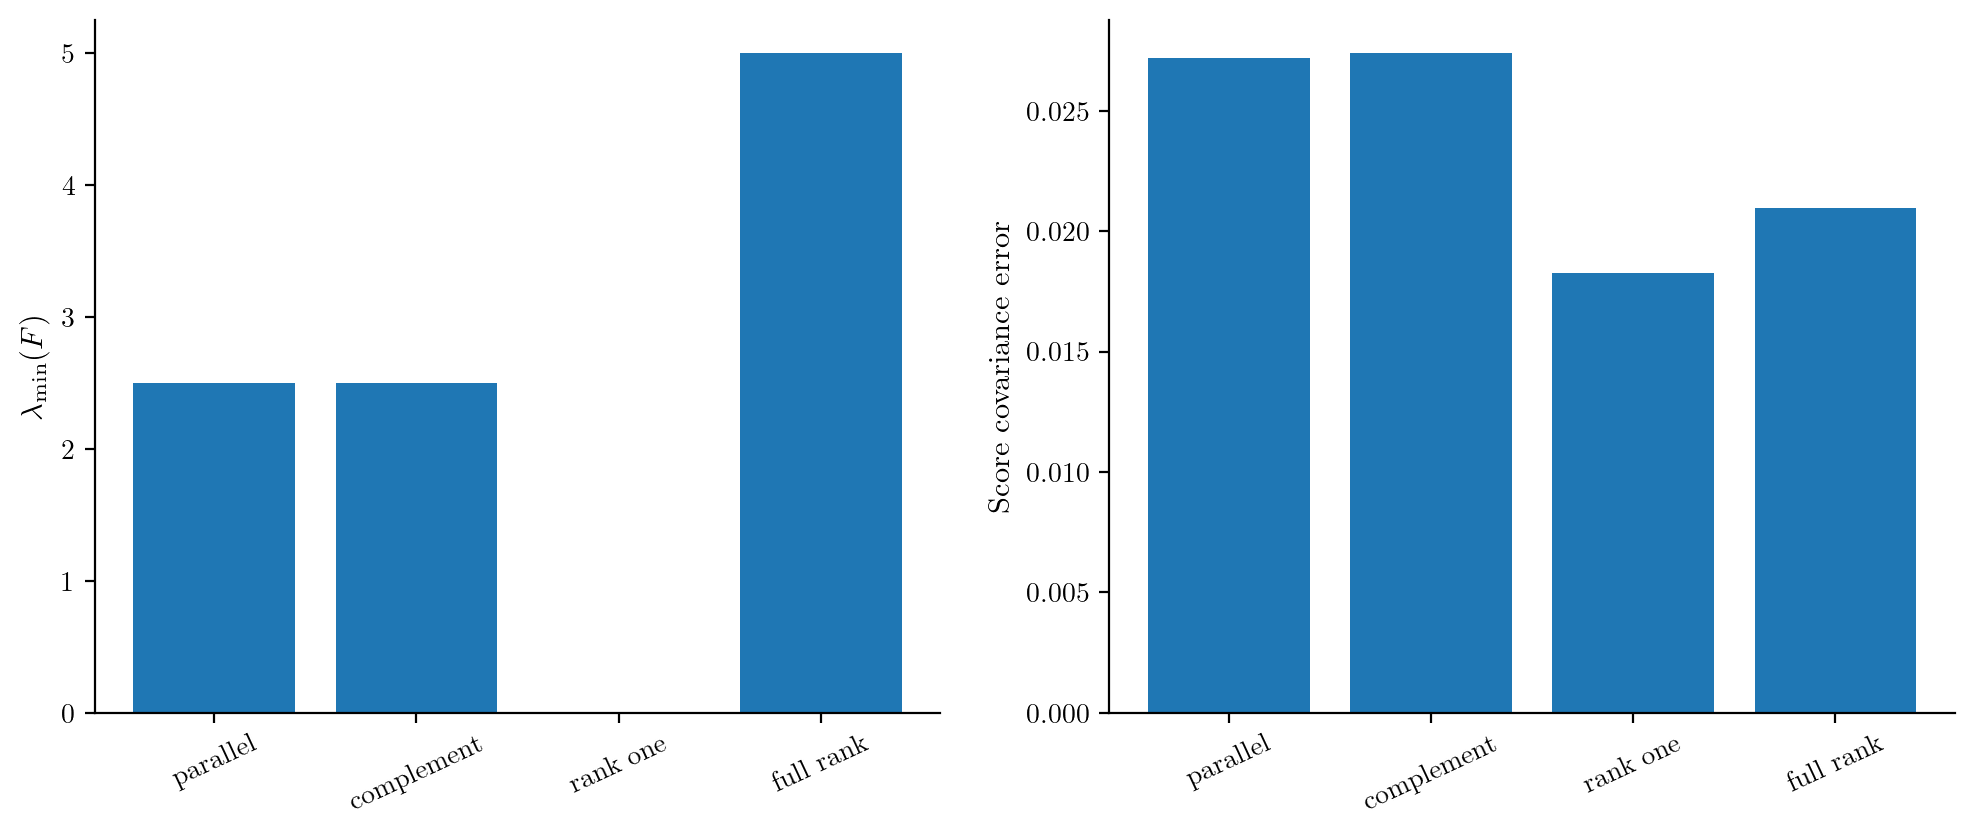

In [4]:
from lib.studies import information_study, tracking_study, scalability_study
info=information_study()
display(info)
assert info.relative_error.max()<.08
fig,axs=plt.subplots(1,2,figsize=(12,4.5))
axs[0].bar(info.input,info.lambda_min);axs[0].set_ylabel(r'$\lambda_{\min}(F)$')
axs[1].bar(info.input,info.relative_error);axs[1].set_ylabel('Score covariance error')
for ax in axs: ax.tick_params(axis='x',rotation=25)
save(fig,OUT/'theory_information');plt.show()


## Tracking, forgetting, and drift
Inputs are preassigned equal-norm coordinate cycles. The variance is fixed at the true value; no EM is used. All terms of Eq. (28) use the complete history. Invalid theorem conditions are retained and marked; a missing bound is not a failure of the theorem. The repeated-noise check below uses one predeclared terminal time, not simultaneous coverage over the curve.

,drift,beta,t,error,error_se,bound,valid,gamma,drift_term,noise_term,initialization,ceiling,violations,repeats
0,0.000,1.00,12,0.045542,0.002228,0.419633,True,400.000000,0.000000,118.236969,0.0,1.0,0.0,128
1,0.000,1.00,48,0.022372,0.001144,0.173428,True,1600.000000,0.000000,236.473938,0.0,1.0,0.0,128
2,0.000,1.00,120,0.014558,0.000725,0.103113,True,4000.000000,0.000000,373.898125,0.0,1.0,0.0,128
3,0.000,1.00,480,0.007646,0.000367,0.049029,True,16000.000000,0.000000,747.796251,0.0,1.0,0.0,128
4,0.000,0.97,12,0.045742,0.002107,0.451338,True,334.968928,0.000000,104.168810,0.0,1.0,0.0,128
5,0.000,0.97,48,0.024702,0.001207,0.201073,True,840.533260,0.000000,140.714838,0.0,1.0,0.0,128
6,0.000,0.97,120,0.018975,0.000858,0.156973,True,1065.813808,0.000000,144.605033,0.0,1.0,0.0,128
7,0.000,0.97,480,0.020917,0.000892,0.152355,True,1094.105572,0.000000,144.653404,0.0,1.0,0.0,128
8,0.002,1.00,12,0.046463,0.002093,0.444276,True,400.000000,4.807698,118.236969,0.0,1.0,0.0,128
9,0.002,1.00,48,0.052924,0.001508,0.243532,True,1600.000000,76.868259,236.473938,0.0,1.0,0.0,128


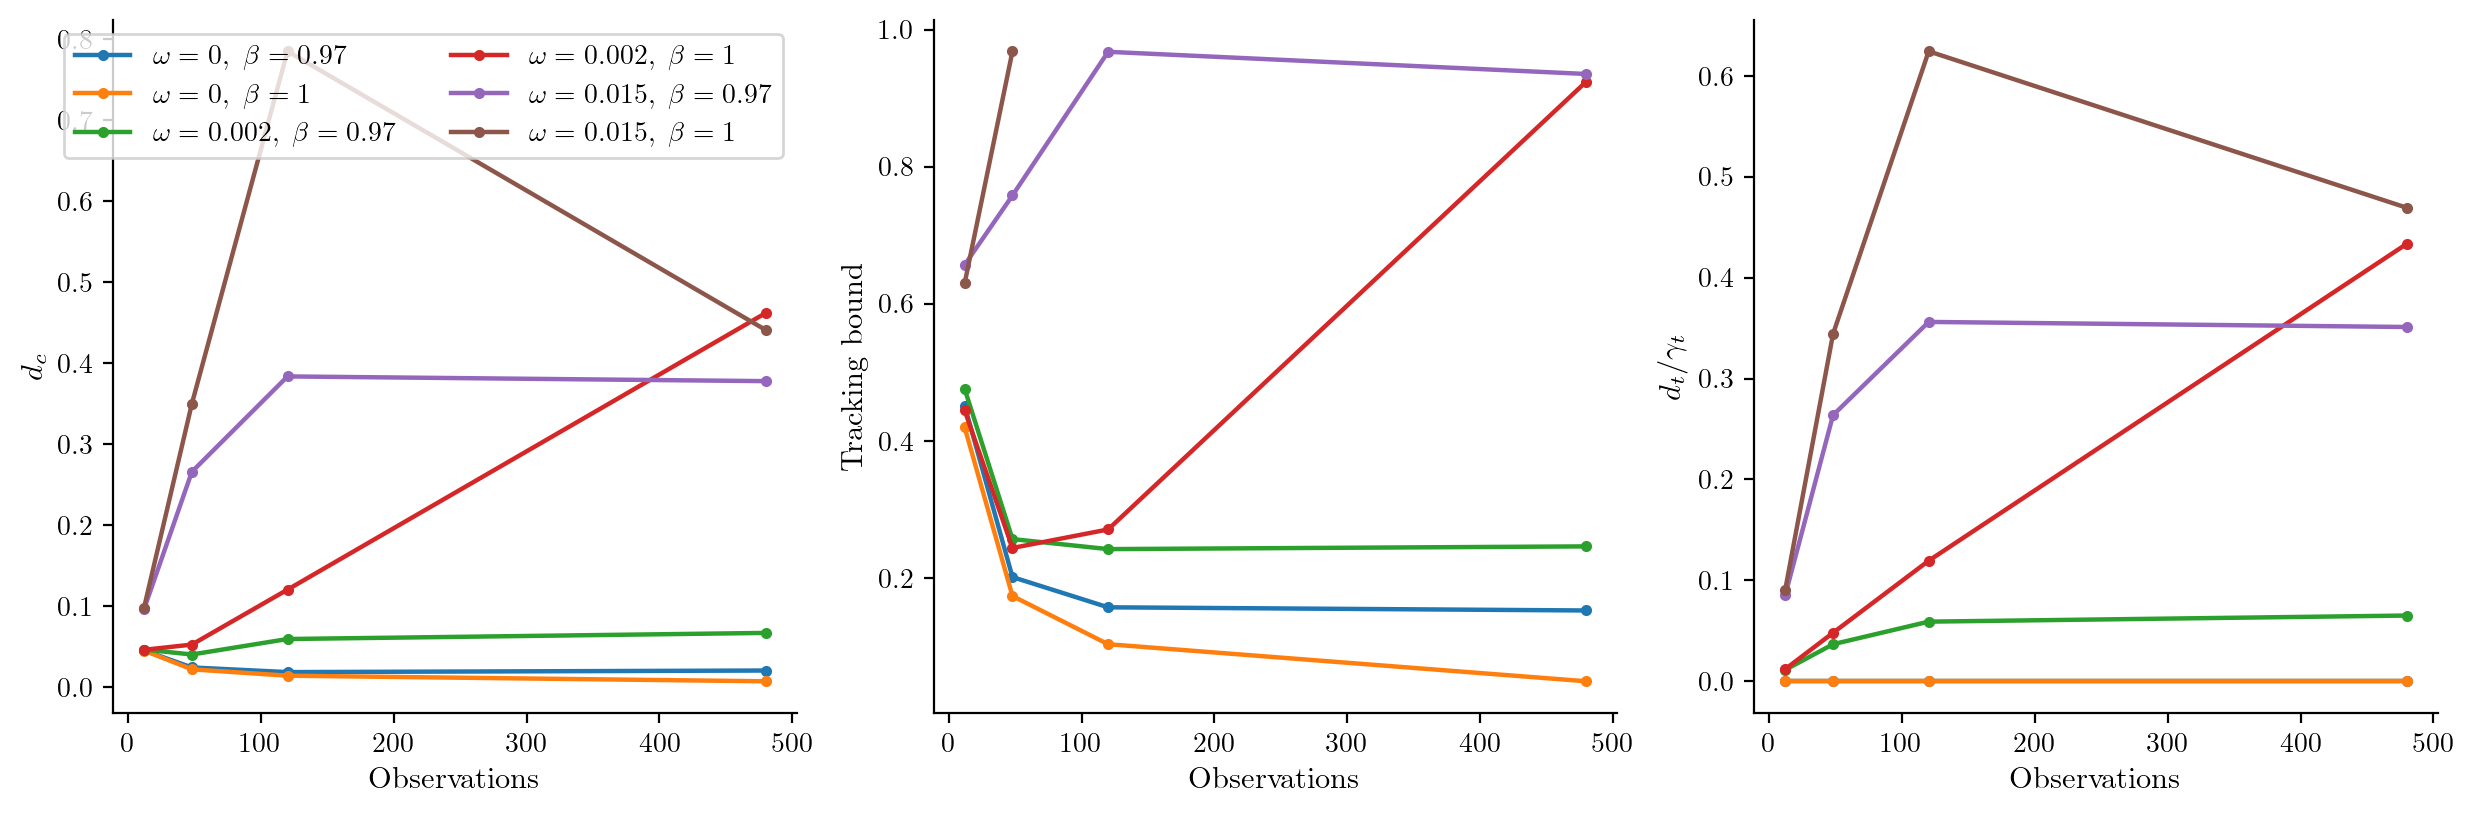

In [5]:
track=tracking_study(T=480,repeats=128)
display(track)
terminal=track[(track.drift==0)&(track.beta==1)&(track.t==480)].iloc[0]
assert bool(terminal.valid), 'Nonvacuous fixed-time fixture is required'
assert terminal.violations==0
# Exact one-sided 95% binomial upper bound for zero violations.
violation_upper=1-.05**(1/int(terminal.repeats))
assert violation_upper<.05
assert (~track.valid).any(), 'Stress cases must include invalid conditions'
fig,axs=plt.subplots(1,3,figsize=(15,4.5))
for (drift,beta),g in track.groupby(['drift','beta']):
    label=rf'$\omega={drift:g},\ \beta={beta:g}$'
    axs[0].plot(g.t,g.error,marker='.',label=label)
    axs[1].plot(g.t,g.bound,marker='.',label=label)
    axs[2].plot(g.t,g.drift_term/g.gamma,marker='.',label=label)
axs[0].set_ylabel(r'$d_c$');axs[1].set_ylabel('Tracking bound');axs[2].set_ylabel(r'$d_t/\gamma_t$')
for ax in axs:ax.set_xlabel('Observations')
axs[0].legend(ncol=2);save(fig,OUT/'theory_tracking');plt.show()
track.to_csv(OUT/'theory_tracking.csv',index=False)


## Directional uncertainty and certified bounds
Appendix I has equal modes and equal ball radii but different directional risks. Continuous tail integration is used for the reference thresholds; accurate moment quadrature alone does not certify a discrete tail quantile. Eq. (33) returns feasible and dual values, with a separate optimization gap.

,direction,risk,ball,hpd,gap
0,e2,0.063630,0.519344,0.628289,6.801366e-10
1,e3,0.006254,0.519344,0.198682,6.801366e-10


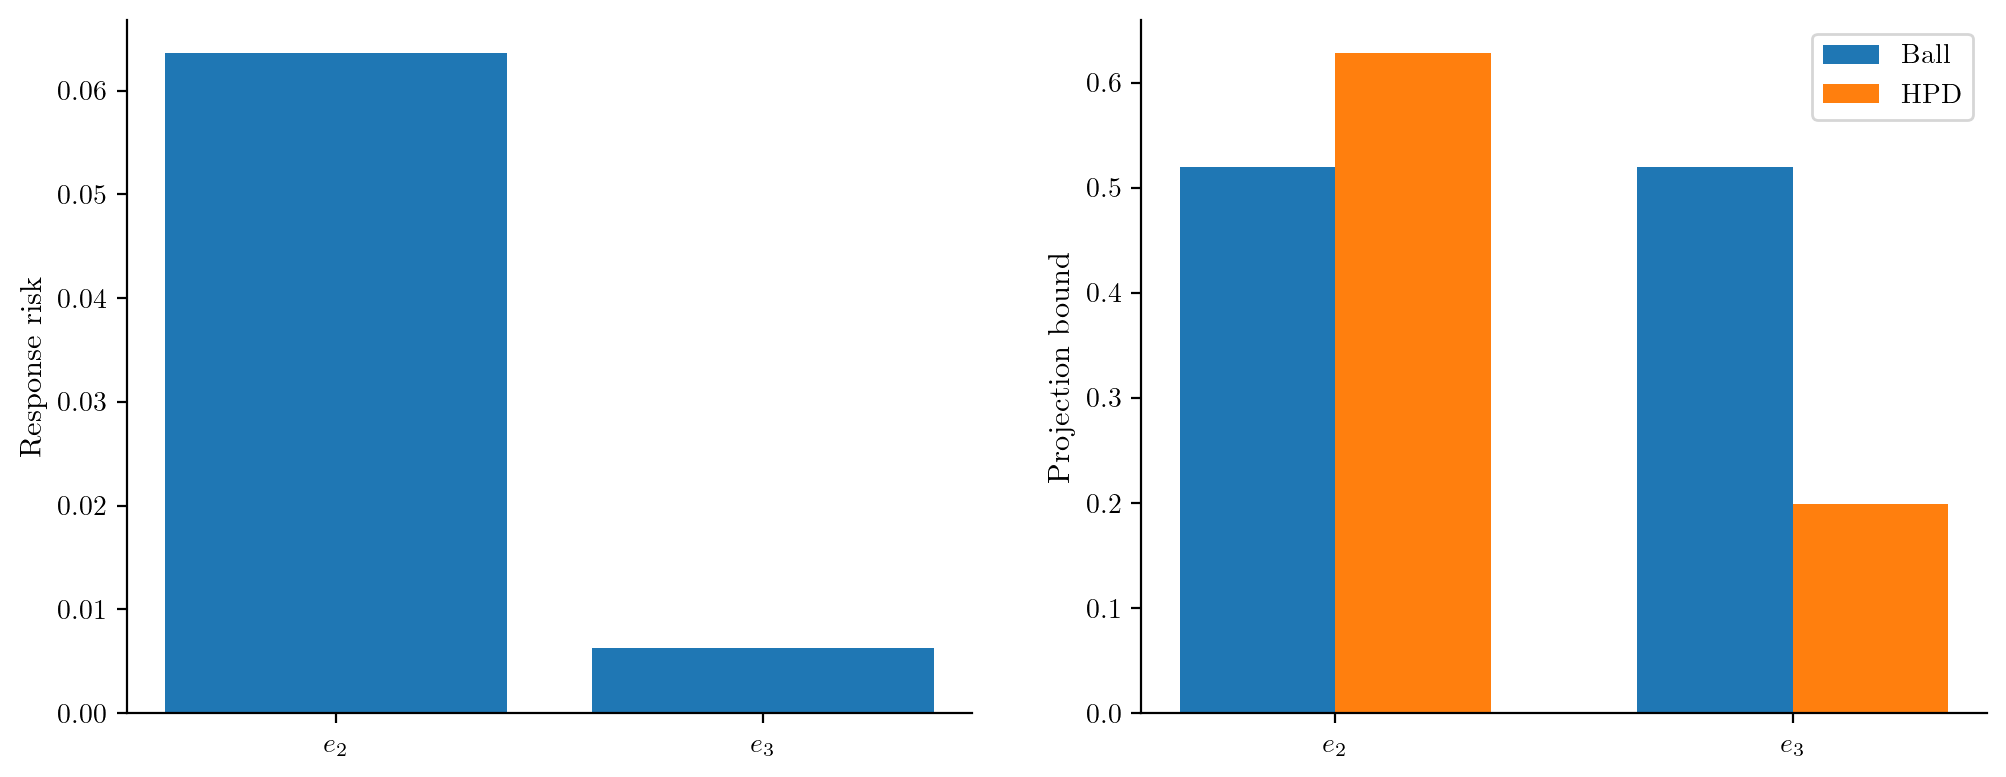

In [6]:
from lib.moments import quadrature, sample_bingham, chain_diagnostics
from lib.reference import rank_one_regions_gr13
from lib.theory import regional_bound
from lib.geometry import risk
A=np.diag([0.,-8.,-80.]);q=quadrature(A);reg=rank_one_regions_gr13(A)
P=np.diag([1.,0.,0.]);rows=[]
for i in (1,2):
    v=np.eye(3)[:,i];B=np.outer(v,v)
    ball=regional_bound(B,P,1-reg.radius**2,1)
    hpd=regional_bound(B,A,-reg.hpd_loss,1)
    rows.append(dict(direction=f'e{i+1}',risk=risk(q.mean,v),ball=np.sqrt(ball.upper),hpd=np.sqrt(hpd.upper),gap=max(ball.gap,hpd.gap)))
directional=pd.DataFrame(rows);display(directional)
assert np.max(abs(q.mean.diagonal()-[.92541154,.06829456,.00629390]))<1e-7
assert abs(reg.radius-.519344)<1e-6 and abs(reg.hpd_loss-3.157974)<1e-6
assert directional.gap.max()<1e-7
assert directional.hpd.iloc[0]>directional.ball.iloc[0] and directional.hpd.iloc[1]<directional.ball.iloc[1]
fig,axs=plt.subplots(1,2,figsize=(12,4.5))
x=np.arange(2)
axs[0].bar(x,directional.risk);axs[0].set_xticks(x,[r'$e_2$',r'$e_3$']);axs[0].set_ylabel('Response risk')
axs[1].bar(x-.17,directional.ball,width=.34,label='Ball');axs[1].bar(x+.17,directional.hpd,width=.34,label='HPD')
axs[1].set_xticks(x,[r'$e_2$',r'$e_3$']);axs[1].set_ylabel('Projection bound');axs[1].legend()
save(fig,OUT/'theory_directional');plt.show()


## Numerical moments and EM
Three independent chains at `n=16, k=3` with spectral gaps up to 600 are checked in the required tests (12,000 retained draws and 4,000 burn-in sweeps per chain, real and complex). Here a separate small-dimensional reference reports moment error and chain diagnostics. Spectral moments, raw samples, credible tails, and normalizer estimates have different error budgets.

Frozen-prior conditional and marginal EM tests verify predictive likelihood ascent using deterministic E-steps, including the variance floor and pooled boundary. A separate changing-prior test verifies that historical data are not corrected twice. Sampled E-steps have no automatic ascent guarantee; case-study noise fits are labelled accordingly.

In [7]:
chains=[sample_bingham(A,1,seed,draws=24000,burnin=3000) for seed in (80,81,82)]
diag=chain_diagnostics(chains)
display(diag)
assert diag['max_rhat']<1.05 and diag['min_ess']>100
moment_error=max(np.max(abs(c.mean-q.mean)) for c in chains)
assert moment_error<max(.007,5*diag['max_mcse'])


{'max_rhat': 1.0007026975459008,
 'max_mean_difference': 0.002296355394263677,
 'max_standardized_difference': np.float64(0.5906998429699951),
 'min_ess': 1033.3186288425604,
 'max_mcse': 0.0028725237816521706}

## Cost and scalability
Dense parameter storage and eigendecomposition are measured at dimensions 8 through 128, rank 3. These checks establish implementability at the tested sizes, not large-scale optimality. Posterior sampling, regional optimization, and EM add costs reported separately in the applications.

,n,k,seconds,parameter_bytes,finite,trace
0,8,3,0.000442,512,True,0.000000e+00
1,16,3,0.000359,2048,True,8.881784e-16
2,32,3,0.000461,8192,True,5.329071e-15
3,64,3,0.001057,32768,True,3.552714e-15
4,128,3,0.002694,131072,True,-7.105427e-15


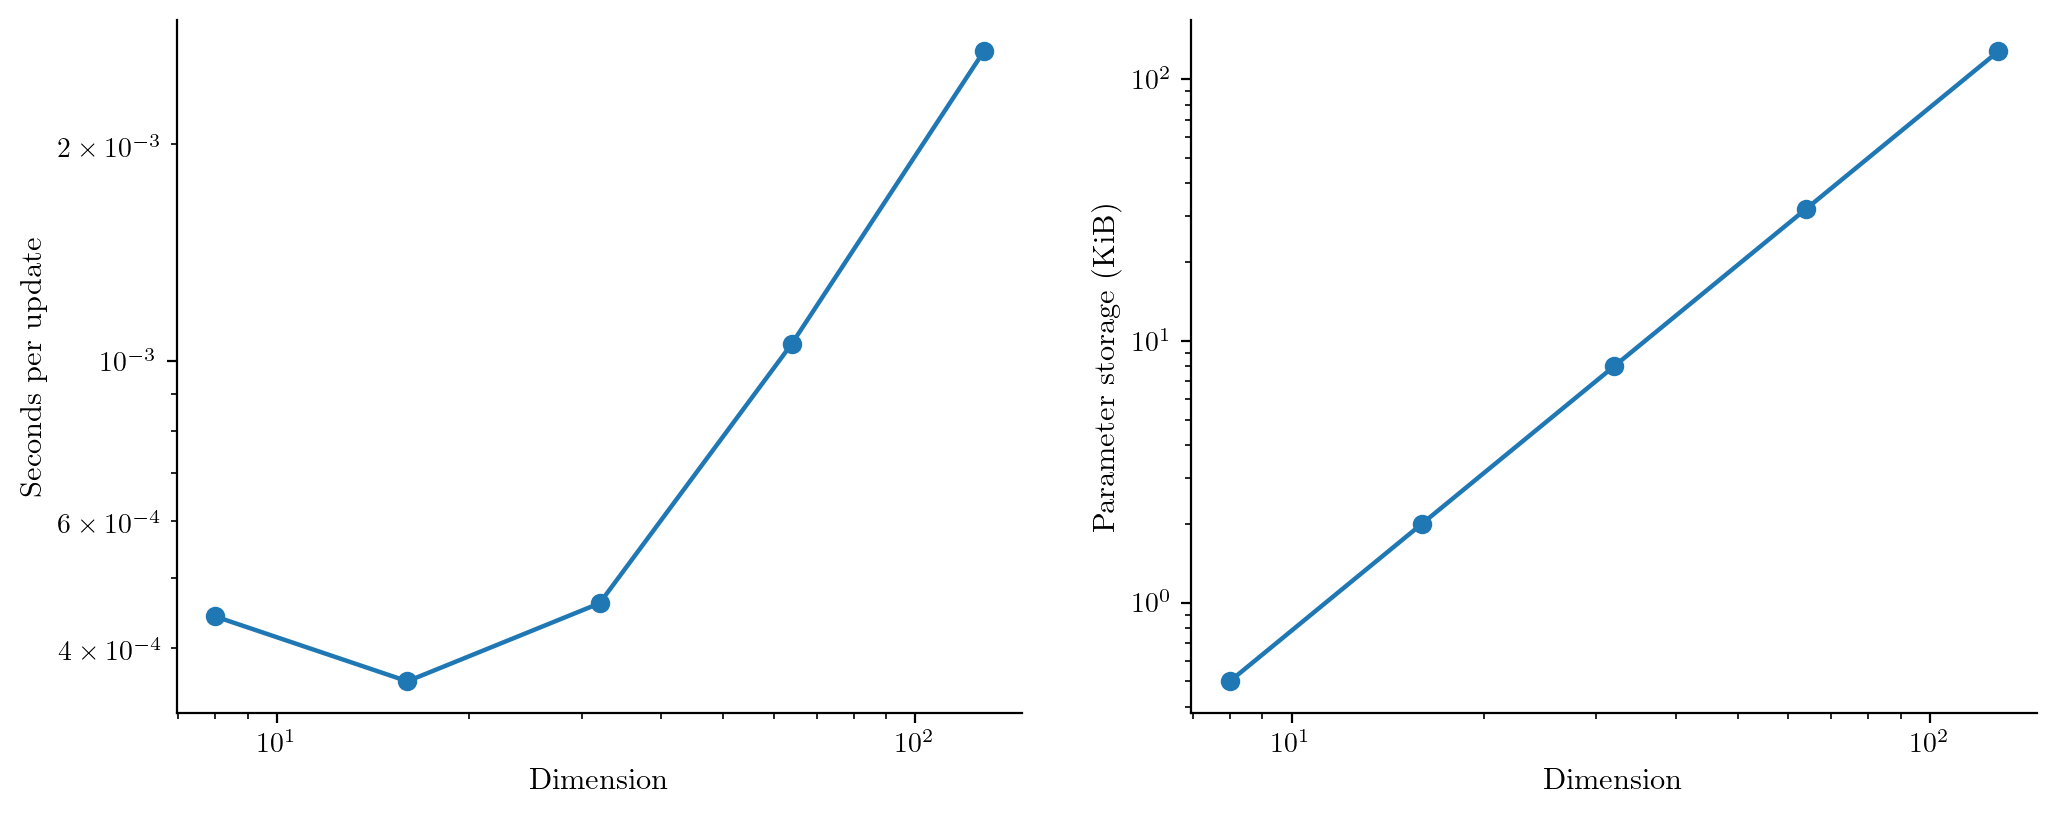

In [8]:
scale=scalability_study();display(scale)
assert scale.finite.all() and np.max(abs(scale.trace))<1e-8
assert np.allclose(scale.parameter_bytes,8*scale.n**2)
fig,axs=plt.subplots(1,2,figsize=(12,4.5))
axs[0].loglog(scale.n,scale.seconds,'o-');axs[0].set_ylabel('Seconds per update')
axs[1].loglog(scale.n,scale.parameter_bytes/1024,'o-');axs[1].set_ylabel('Parameter storage (KiB)')
for ax in axs:ax.set_xlabel('Dimension')
save(fig,OUT/'theory_scaling');plt.show()


## Validation certificate
Only reaching this cell writes a passing certificate for the exact numerical core. Example notebook generation and execution verify this hash. Empirical coverage and baseline performance in the case studies remain experimental outcomes, not assertions to force a desired ranking.

In [9]:
import platform, scipy, matplotlib
assert core_hash(ROOT)==validated_hash, 'Validation sources changed during execution; rerun'
certificate=dict(status='passed',core_hash=validated_hash,tests=tests,
    seed=20,tracking_repeats=128,tracking_terminal=480,
    fixed_time_violations=int(terminal.violations),violation_upper_95=violation_upper,
    sampler=diag,moment_error=float(moment_error),dimensions=scale.n.tolist(),
    seconds=time.perf_counter()-started,
    versions=dict(python=platform.python_version(),numpy=np.__version__,scipy=scipy.__version__,matplotlib=matplotlib.__version__),
    scope='Finite deterministic checks, stochastic diagnostics and stated scalability budgets; no universal guarantee')
(OUT/'validation.json').write_text(json.dumps(certificate,indent=2))
display(certificate)


{'status': 'passed',
 'core_hash': '2ea66397d81e79751745b67eb44eb4c857feede273068e733b159f0e884acbc7',
 'tests': 178,
 'seed': 20,
 'tracking_repeats': 128,
 'tracking_terminal': 480,
 'fixed_time_violations': 0,
 'violation_upper_95': 0.023132405251746757,
 'sampler': {'max_rhat': 1.0007026975459008,
  'max_mean_difference': 0.002296355394263677,
  'max_standardized_difference': np.float64(0.5906998429699951),
  'min_ess': 1033.3186288425604,
  'max_mcse': 0.0028725237816521706},
 'moment_error': 0.003521279454262921,
 'dimensions': [8, 16, 32, 64, 128],
 'seconds': 112.94107022302342,
 'versions': {'python': '3.12.14',
  'numpy': '2.3.5',
  'scipy': '1.17.0',
  'matplotlib': '3.10.8'},
 'scope': 'Finite deterministic checks, stochastic diagnostics and stated scalability budgets; no universal guarantee'}